## 0. 환경설정

In [11]:
# 환경 설정 및 라이브러리 import
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from datetime import datetime, timedelta
import os
import warnings
warnings.filterwarnings('ignore')

# pyKRX 관련
from pykrx import stock
from pykrx import bond

# 기술적 지표 계산
import talib
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
import platform
import os

# Find the path to the font file
font_path = '~/Library/Fonts/NanumGothic.otf'
fm.fontManager.addfont(font_path)

# 2. Set the font family for Matplotlib
plt.rc('font', family='NanumGothic')

# 추가 한글 지원 설정
plt.rcParams['font.sans-serif'] = plt.rcParams['font.family']
plt.rcParams['axes.unicode_minus'] = False

print("✅ 환경 설정 완료")
print(f"📁 분석 결과 로딩 경로: {os.path.abspath('./analysis')}")


✅ 환경 설정 완료
📁 분석 결과 로딩 경로: ~/Code/ai-hedge-fund/finance-data-analysis/analysis/analysis


In [15]:
%pip install xgboost

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.0/2.0 MB 4.7 MB/s eta 0:00:00a 0:00:010m
Note: you may need to restart the kernel to use updated packages.


## 1. 분석데이터로딩

In [12]:
import os
import pandas as pd

base_dir = os.path.abspath(os.getcwd())
analysis_dir = os.path.join(base_dir, 'analysis')

print(f"📁 분석 디렉터리: {analysis_dir}")

def load_analysis_csv(ticker: str, name: str) -> pd.DataFrame:
    """
    Load analysis CSV file with name pattern analysis/{ticker}_{name}.csv.
    - ticker: e.g., '005930'
    - name: e.g., '삼성전자'
    Returns a DataFrame if exists, otherwise raises FileNotFoundError.
    """
    filename = f"{ticker}_{name}.csv"
    path = os.path.join(analysis_dir, filename)
    if not os.path.exists(path):
        raise FileNotFoundError(f"분석 파일이 없습니다: {path}")
    df = pd.read_csv(path)
    print(f"✅ 로드 완료: {filename}  (rows={len(df)}, cols={len(df.columns)})")
    return df



📁 분석 디렉터리: ~/Code/ai-hedge-fund/finance-data-analysis/analysis/analysis


In [ ]:

df.columns

Index(['날짜', 'RSI', '52주_고가_대비_주가', '52주_저가_대비_주가', 'close', 'ma5', 'ma20',
       'ma60', 'MA60_MA20', 'MA20_MA5', 'MA5_MA1', 'ma20_ma60', 'Golden_Cross',
       'bb_upper', 'bb_middle', 'bb_lower', 'bb_width', 'atr', 'adx',
       'daily_return', 'weekly_return', '20week_return', 'years',
       'volume(std)', 'volatility', 'weekly_up', '20week_up',
       'weekly_up_count', '20week_up_count', 'hurst_exponent',
       'diff_with_index'],
      dtype='object')

In [13]:
# 2. 주별 수익률 랭킹 생성 및 저장 (원본 컬럼 유지)
import os
import pandas as pd

# 분석 CSV 목록 수집 (analysis/analysis 내 *.csv)
files = [f for f in os.listdir(analysis_dir) if f.endswith('.csv')]
print(f"📄 파일 개수: {len(files)}")

all_weekly_list = []
for filename in files:
    try:
        ticker, name = os.path.splitext(filename)[0].split('_', 1)
        df = load_analysis_csv(ticker, name).dropna()
        if '날짜' not in df.columns or 'weekly_return' not in df.columns:
            continue
        df['날짜'] = pd.to_datetime(df['날짜'])
        df = df.sort_values('날짜').set_index('날짜')
        # 주별로 하나만 남김: 주간 마지막 관측치 사용 (금요일 기준)
        weekly = df.resample('W-FRI').last()
        # prev_weekly_return 추가
        weekly['prev_weekly_return'] = weekly['weekly_return'].shift(1)
        # 메타 정보 추가
        weekly['ticker'] = ticker
        weekly['name'] = name
        # weekly는 모든 원본 컬럼을 유지
        weekly = weekly.dropna(subset=['weekly_return'])
        all_weekly_list.append(weekly)
    except Exception as e:
        print(f"⚠️ {filename} 처리 중 오류: {e}")
        continue

if len(all_weekly_list) == 0:
    raise RuntimeError('주간 데이터가 비어 있습니다. 분석 CSV와 컬럼명을 확인하세요.')

all_weekly = pd.concat(all_weekly_list).reset_index().rename(columns={'index': '날짜'})

# 주별 수익률 랭크 (내림차순, 1위가 최고)
all_weekly['weekly_rank'] = (
    all_weekly.groupby('날짜')['weekly_return']
    .rank(ascending=False, method='min')
    .astype(int)
)

# 전체 주간 데이터 저장 (원본 컬럼 포함)
root_dir = os.path.abspath(os.getcwd())
analysis_dataset_dir = os.path.join(root_dir, 'analysis', 'dataset')
os.makedirs(analysis_dataset_dir, exist_ok=True)

full_save_path = os.path.join(analysis_dataset_dir, 'weekly_full.csv')
all_weekly.to_csv(full_save_path, index=False)
print(f"✅ 전체 주간 데이터 저장: {full_save_path}")

# 상위 3위만 별도 저장
top3 = all_weekly[all_weekly['weekly_rank'] <= 3].sort_values(['날짜', 'weekly_rank', 'ticker'])

top3_save_path = os.path.join(analysis_dataset_dir, 'weekly_top3.csv')
top3.to_csv(top3_save_path, index=False)
print(f"✅ Top3 저장: {top3_save_path}")

display(all_weekly.head(), all_weekly.shape, top3.head(), top3.shape)


📄 파일 개수: 1089
✅ 로드 완료: 000240_한국앤컴퍼니.csv  (rows=3000, cols=31)
✅ 로드 완료: 024900_디와이덕양.csv  (rows=3000, cols=31)
✅ 로드 완료: 139480_이마트.csv  (rows=3000, cols=31)
✅ 로드 완료: 086790_하나금융지주.csv  (rows=3000, cols=31)
✅ 로드 완료: 010620_HD현대미포.csv  (rows=3000, cols=31)
✅ 로드 완료: 001430_세아베스틸지주.csv  (rows=3000, cols=31)
✅ 로드 완료: 361670_삼영에스앤씨.csv  (rows=7333, cols=31)
✅ 로드 완료: 106520_노블엠앤비.csv  (rows=7333, cols=31)
✅ 로드 완료: 084680_이월드.csv  (rows=3000, cols=31)
✅ 로드 완료: 200780_비씨월드제약.csv  (rows=7333, cols=31)
✅ 로드 완료: 001680_대상.csv  (rows=3000, cols=31)
✅ 로드 완료: 267790_배럴.csv  (rows=7333, cols=31)
✅ 로드 완료: 377300_카카오페이.csv  (rows=966, cols=31)
✅ 로드 완료: 009460_한창제지.csv  (rows=3000, cols=31)
✅ 로드 완료: 282720_금양그린파워.csv  (rows=7333, cols=31)
✅ 로드 완료: 009180_한솔로지스틱스.csv  (rows=3000, cols=31)
✅ 로드 완료: 00680K_미래에셋증권2우B.csv  (rows=1862, cols=31)
✅ 로드 완료: 033560_블루콤.csv  (rows=7333, cols=31)
✅ 로드 완료: 000480_CR홀딩스.csv  (rows=3000, cols=31)
✅ 로드 완료: 039560_다산네트웍스.csv  (rows=7333, cols=31)
✅ 로드 완료: 042500_링네트.csv  

,날짜,RSI,52주_고가_대비_주가,52주_저가_대비_주가,close,ma5,ma20,ma60,MA60_MA20,MA20_MA5,...,weekly_up,20week_up,weekly_up_count,20week_up_count,hurst_exponent,diff_with_index,prev_weekly_return,ticker,name,weekly_rank
0,2014-08-01,56.758556,0.850000,1.192208,22950.0,22970.0,22332.5,22490.000000,1.007053,0.972246,...,0.0,1.0,1.0,8.0,0.547354,-1.025813,NaN,000240,한국앤컴퍼니,212
1,2014-08-08,32.484018,0.788889,1.106494,21300.0,22100.0,22485.0,22570.000000,1.003780,1.017421,...,-1.0,1.0,0.0,8.0,0.547354,-1.054351,-0.006515,000240,한국앤컴퍼니,475
2,2014-08-15,33.241662,0.781481,1.096104,21100.0,21340.0,22425.0,22562.500000,1.006132,1.050843,...,-1.0,1.0,0.0,7.0,0.547354,-1.036876,-0.074611,000240,한국앤컴퍼니,426
3,2014-08-22,40.369426,0.788889,1.106494,21300.0,21250.0,22005.0,22490.833333,1.022078,1.035529,...,0.0,0.0,0.0,2.0,0.547354,-0.987406,-0.032637,000240,한국앤컴퍼니,162
4,2014-08-29,50.349846,0.809259,1.135065,21850.0,21740.0,21690.0,22365.000000,1.031120,0.997700,...,1.0,1.0,4.0,4.0,0.547354,-0.980263,0.009434,000240,한국앤컴퍼니,137


(334704, 35)

,날짜,RSI,52주_고가_대비_주가,52주_저가_대비_주가,close,ma5,ma20,ma60,MA60_MA20,MA20_MA5,...,weekly_up,20week_up,weekly_up_count,20week_up_count,hurst_exponent,diff_with_index,prev_weekly_return,ticker,name,weekly_rank
3510,2014-08-01,86.285032,1.000000,4.710253,3170.0,2636.0,1953.5,1412.483333,0.723053,0.741085,...,1.0,1.0,5.0,12.0,0.552482,-0.464403,NaN,084680,이월드,1
114636,2014-08-01,76.780779,0.128014,1.563964,6345.0,5479.6,5034.6,4868.983333,0.967104,0.918790,...,1.0,-1.0,4.0,10.0,0.572720,-0.714929,NaN,028670,팬오션,2
190314,2014-08-01,90.862882,0.972924,1.814815,5390.0,4967.0,3895.0,3627.583333,0.931344,0.784176,...,1.0,1.0,5.0,18.0,0.603364,-0.729759,NaN,016610,DB증권,3
169288,2014-08-08,87.186573,0.971773,1.834787,3787.0,3480.0,2567.1,2315.766667,0.902094,0.737672,...,1.0,1.0,5.0,14.0,0.568944,-0.641788,0.206074,011000,진원생명과학,1
168703,2014-08-08,68.248904,0.432601,4.000657,1175737.0,1143688.2,829549.5,695371.183333,0.838252,0.725328,...,1.0,1.0,5.0,14.0,0.596048,-0.665737,0.027014,025620,제이준코스메틱,2


(1755, 35)

## 머신러닝 준비단계: XGBoost를 위한 데이터 정제

In [16]:
# 3. 6주 래그 피처 생성, 라벨 생성, 시계열 분할, XGBoost 학습/검증
import numpy as np
from typing import List

# 입력 데이터: all_weekly (위 셀에서 생성됨)
weekly_df = all_weekly.copy()
weekly_df['날짜'] = pd.to_datetime(weekly_df['날짜'])
weekly_df = weekly_df.sort_values(['날짜', 'ticker']).reset_index(drop=True)

# 숫자형 컬럼만 선택 (라벨, 식별자 제외)
exclude_cols: List[str] = ['날짜', 'ticker', 'name']
label_col = 'weekly_rank'
value_cols = [c for c in weekly_df.columns if c not in exclude_cols]

# 6주 래그 피처 생성 (티커별)
lag_weeks = [1, 2, 3, 4, 5, 6]
weekly_df = weekly_df.set_index('날짜')

lagged_parts = []
for ticker, g in weekly_df.groupby('ticker'):
    g = g.sort_index()
    # shift in weekly frequency; index is weekly already
    for col in value_cols:
        if col == label_col:
            continue
        if not np.issubdtype(g[col].dtype, np.number):
            continue
        for k in lag_weeks:
            g[f'{col}_lag{k}'] = g[col].shift(k)
    # 라벨: top3 여부 (1/0)
    g['label_top3'] = (g[label_col] <= 3).astype(int)
    lagged_parts.append(g)

feat_df = pd.concat(lagged_parts).reset_index()  # bring back '날짜'

# 학습용 피처 선택: *_lag{1..6}
feature_cols = [c for c in feat_df.columns if any(c.endswith(f'_lag{k}') for k in lag_weeks)]

# 유효 행 필터: 최근 6주 래그가 모두 존재해야 함
feat_df = feat_df.dropna(subset=feature_cols)

# 시계열 학습/검증 분할 (마지막 15% 주를 검증으로)
unique_weeks = np.array(sorted(feat_df['날짜'].unique()))
split_idx = int(len(unique_weeks) * 0.85)
train_weeks = set(unique_weeks[:split_idx])
valid_weeks = set(unique_weeks[split_idx:])

train_df = feat_df[feat_df['날짜'].isin(train_weeks)].copy()
valid_df = feat_df[feat_df['날짜'].isin(valid_weeks)].copy()

print(f"학습 주 수: {len(train_weeks)}, 검증 주 수: {len(valid_weeks)}")
print(f"학습 샘플: {len(train_df):,}, 검증 샘플: {len(valid_df):,}")

# XGBoost 학습
from xgboost import XGBClassifier
from sklearn.metrics import roc_auc_score, average_precision_score, classification_report

X_train = train_df[feature_cols].values
y_train = train_df['label_top3'].values
X_valid = valid_df[feature_cols].values
y_valid = valid_df['label_top3'].values

xgb = XGBClassifier(
    n_estimators=600,
    max_depth=6,
    learning_rate=0.03,
    subsample=0.8,
    colsample_bytree=0.8,
    objective='binary:logistic',
    eval_metric='auc',
    tree_method='hist',
    random_state=42,
)

xgb.fit(X_train, y_train)

valid_pred_proba = xgb.predict_proba(X_valid)[:, 1]
valid_auc = roc_auc_score(y_valid, valid_pred_proba)
valid_ap = average_precision_score(y_valid, valid_pred_proba)
print(f"Validation AUC: {valid_auc:.4f} | AP: {valid_ap:.4f}")

# 검증 기간 주별 Top-N 예측 생성 (예: Top3 후보)
valid_df['pred_proba'] = valid_pred_proba
valid_top3_by_week = (
    valid_df.sort_values(['날짜', 'pred_proba'], ascending=[True, False])
            .groupby('날짜').head(3)
            .sort_values(['날짜', 'pred_proba'], ascending=[True, False])
            [['날짜', 'ticker', 'name', 'pred_proba', 'weekly_rank', 'label_top3']]
)

# 산출물 저장
preds_path = os.path.join(analysis_dataset_dir, 'xgb_valid_top3.csv')
valid_top3_by_week.to_csv(preds_path, index=False)

feat_save_path = os.path.join(analysis_dataset_dir, 'xgb_features.csv')
feat_df.to_csv(feat_save_path, index=False)

print(f"✅ 예측 저장: {preds_path}")
print(f"✅ 피처 저장: {feat_save_path}")

display(valid_top3_by_week.head(), valid_top3_by_week.shape)


학습 주 수: 486, 검증 주 수: 86
학습 샘플: 273,141, 검증 샘플: 53,890
Validation AUC: 0.7874 | AP: 0.0337
✅ 예측 저장: ~/Code/ai-hedge-fund/finance-data-analysis/analysis/analysis/dataset/xgb_valid_top3.csv
✅ 피처 저장: ~/Code/ai-hedge-fund/finance-data-analysis/analysis/analysis/dataset/xgb_features.csv


,날짜,ticker,name,pred_proba,weekly_rank,label_top3
254243,2024-03-01,077500,유니퀘스트,0.093265,612,0
156521,2024-03-01,012170,아센디오,0.081987,621,0
60055,2024-03-01,003535,한화투자증권우,0.068569,15,0
21560,2024-03-08,001250,GS글로벌,0.086638,575,0
60056,2024-03-08,003535,한화투자증권우,0.041760,332,0


(258, 6)

In [24]:
# 4. 롤링 윈도우 시계열 검증 (AUC / AP)
import numpy as np
from sklearn.metrics import roc_auc_score, average_precision_score
from xgboost import XGBClassifier

# 주 단위 배열 준비
weeks_sorted = np.array(sorted(feat_df['날짜'].unique()))
num_weeks = len(weeks_sorted)

# 설정: 최소 학습 주, 폴드 수
min_train_weeks = max(156, int(num_weeks * 0.5))  # 최소 3년 약 156주, 또는 50%
n_folds = 5

fold_len = max(4, (num_weeks - min_train_weeks) // n_folds)  # 각 폴드 검증 주 길이
metrics = []

for i in range(n_folds):
    train_end_idx = min_train_weeks + i * fold_len
    valid_end_idx = min(train_end_idx + fold_len, num_weeks)
    if valid_end_idx <= train_end_idx:
        break

    train_weeks_cv = set(weeks_sorted[:train_end_idx])
    valid_weeks_cv = set(weeks_sorted[train_end_idx:valid_end_idx])

    train_cv = feat_df[feat_df['날짜'].isin(train_weeks_cv)]
    valid_cv = feat_df[feat_df['날짜'].isin(valid_weeks_cv)]

    if len(valid_cv) == 0 or len(train_cv) == 0:
        continue

    X_tr = train_cv[feature_cols].values
    y_tr = train_cv['label_top3'].values
    X_va = valid_cv[feature_cols].values
    y_va = valid_cv['label_top3'].values

    model = XGBClassifier(
        n_estimators=600,
        max_depth=6,
        learning_rate=0.03,
        subsample=0.8,
        colsample_bytree=0.8,
        objective='binary:logistic',
        eval_metric='auc',
        tree_method='hist',
        random_state=42,
    )
    model.fit(X_tr, y_tr)

    va_proba = model.predict_proba(X_va)[:, 1]
    auc = roc_auc_score(y_va, va_proba)
    ap = average_precision_score(y_va, va_proba)
    metrics.append({'fold': i+1, 'train_weeks': len(train_weeks_cv), 'valid_weeks': len(valid_weeks_cv), 'AUC': auc, 'AP': ap})

cv_df = pd.DataFrame(metrics)
cv_path = os.path.join(analysis_dataset_dir, 'rolling_cv_metrics.csv')
cv_df.to_csv(cv_path, index=False)

if len(cv_df):
    print(f"✅ 롤링 윈도우 CV 저장: {cv_path}")
    print(cv_df)
    print("----")
    print(f"AUC mean={cv_df['AUC'].mean():.4f} ± {cv_df['AUC'].std():.4f} | AP mean={cv_df['AP'].mean():.4f} ± {cv_df['AP'].std():.4f}")
else:
    print("⚠️ 생성된 CV 폴드가 없습니다. 기간 설정을 확인하세요.")

display(cv_df.head() if len(cv_df) else cv_df)


✅ 롤링 윈도우 CV 저장: ~/Code/ai-hedge-fund/finance-data-analysis/analysis/analysis/dataset/rolling_cv_metrics.csv
   fold  train_weeks  valid_weeks       AUC        AP
0     1          286           57  0.738198  0.021842
1     2          343           57  0.761223  0.020249
2     3          400           57  0.797284  0.038643
3     4          457           57  0.778237  0.029451
4     5          514           57  0.788230  0.042664
----
AUC mean=0.7726 ± 0.0234 | AP mean=0.0306 ± 0.0099


,fold,train_weeks,valid_weeks,AUC,AP
0,1,286,57,0.738198,0.021842
1,2,343,57,0.761223,0.020249
2,3,400,57,0.797284,0.038643
3,4,457,57,0.778237,0.029451
4,5,514,57,0.788230,0.042664


## 1. 추천 종목 (최신)

In [25]:
# 5. 최신 주 예측 및 리스크 계산, 추천 종목 산출
import numpy as np

# 최신 주와 직전 12주 기준 설정
weeks_sorted = np.array(sorted(feat_df['날짜'].unique()))
latest_week = weeks_sorted[-1]
lookback_weeks = 12

# 최신 주 입력 샘플
latest_df = feat_df[feat_df['날짜'] == latest_week].copy()

# 리스크 측정치: 12주 변동성 (weekly_return 기반)
weekly_returns = all_weekly[['날짜', 'ticker', 'weekly_return']].copy()
weekly_returns['날짜'] = pd.to_datetime(weekly_returns['날짜'])
weekly_returns = weekly_returns.sort_values(['ticker', '날짜'])

vol_list = []
for ticker, g in weekly_returns.groupby('ticker'):
    g = g.set_index('날짜').sort_index()
    g['vol12'] = g['weekly_return'].rolling(window=lookback_weeks).std()
    # 최신 주의 변동성만 추출
    vol = g['vol12'].reindex([latest_week]).iloc[0] if latest_week in g.index else np.nan
    vol_list.append({'ticker': ticker, 'vol12': vol})

vol_df = pd.DataFrame(vol_list)
latest_df = latest_df.merge(vol_df, on='ticker', how='left')

# 최신 주 예측: 기존 xgb 모델 재학습(전체 과거 데이터) 후 예측
X_all = train_df[feature_cols].values
y_all = train_df['label_top3'].values
final_xgb = XGBClassifier(
    n_estimators=600,
    max_depth=6,
    learning_rate=0.03,
    subsample=0.8,
    colsample_bytree=0.8,
    objective='binary:logistic',
    eval_metric='auc',
    tree_method='hist',
    random_state=42,
)
final_xgb.fit(X_all, y_all)

latest_df['pred_proba'] = final_xgb.predict_proba(latest_df[feature_cols].values)[:, 1]

# 위험조정 점수: pred / (1 + vol12)
latest_df['risk_adj_score'] = latest_df['pred_proba'] / (1.0 + latest_df['vol12'].fillna(latest_df['vol12'].median()))

# 추천: 위험조정 점수 기준 상위 10개
recommendations = (
    latest_df.sort_values('risk_adj_score', ascending=False)
             .head(10)
             [['날짜', 'ticker', 'name', 'pred_proba', 'vol12', 'risk_adj_score']]
)

reco_path = os.path.join(analysis_dataset_dir, 'latest_recommendations.csv')
recommendations.to_csv(reco_path, index=False)
print(f"✅ 최신 추천 저장: {reco_path}")

display(recommendations)


✅ 최신 추천 저장: ~/Code/ai-hedge-fund/finance-data-analysis/analysis/analysis/dataset/latest_recommendations.csv


,날짜,ticker,name,pred_proba,vol12,risk_adj_score
51,2025-10-17,001515,SK증권우,0.103225,0.159519,0.089024
407,2025-10-17,051630,진양화학,0.069976,0.089801,0.064210
279,2025-10-17,013360,일성건설,0.062900,0.026900,0.061252
76,2025-10-17,002630,오리엔트바이오,0.058326,0.034592,0.056375
102,2025-10-17,003535,한화투자증권우,0.070507,0.265321,0.055723
344,2025-10-17,025620,제이준코스메틱,0.051889,0.217488,0.042620
404,2025-10-17,047400,유니온머티리얼,0.039414,0.185633,0.033243
52,2025-10-17,001520,동양,0.035629,0.113467,0.031998
70,2025-10-17,002220,한일철강,0.031960,0.074220,0.029752
106,2025-10-17,003580,HLB글로벌,0.027030,0.047481,0.025805


## 2. 4% 이상 수익률 종목 예측

In [19]:
# 6. 4% 수익률 분류 모델 (weekly_return >= 0.04)
import numpy as np
from sklearn.metrics import (
    roc_auc_score, average_precision_score, accuracy_score,
    precision_score, recall_score, f1_score, classification_report
)
from xgboost import XGBClassifier

# 라벨 생성: 향후 1주 수익률이 4% 이상 여부
clf_df = feat_df.copy()
clf_df['label_4pct'] = (clf_df['weekly_return'] >= 0.04).astype(int)

# 학습/검증 분할은 기존 주 단위 분할 기준 재사용
X_train = train_df[feature_cols].values
y_train = clf_df.loc[train_df.index, 'label_4pct'].values
X_valid = valid_df[feature_cols].values
y_valid = clf_df.loc[valid_df.index, 'label_4pct'].values

# 모델 학습
clf = XGBClassifier(
    n_estimators=600,
    max_depth=6,
    learning_rate=0.03,
    subsample=0.8,
    colsample_bytree=0.8,
    objective='binary:logistic',
    eval_metric='auc',
    tree_method='hist',
    random_state=42,
)
clf.fit(X_train, y_train)

# 평가
valid_proba = clf.predict_proba(X_valid)[:, 1]
valid_pred = (valid_proba >= 0.5).astype(int)

metrics_4pct = {
    'AUC': roc_auc_score(y_valid, valid_proba),
    'AP': average_precision_score(y_valid, valid_proba),
    'ACC': accuracy_score(y_valid, valid_pred),
    'PREC': precision_score(y_valid, valid_pred, zero_division=0),
    'REC': recall_score(y_valid, valid_pred, zero_division=0),
    'F1': f1_score(y_valid, valid_pred, zero_division=0),
}

print(metrics_4pct)
print(classification_report(y_valid, valid_pred, digits=4, zero_division=0))

# 결과 저장
metrics_path = os.path.join(analysis_dataset_dir, 'metrics_4pct.json')
import json
with open(metrics_path, 'w') as f:
    json.dump(metrics_4pct, f, indent=2)

valid_4pct = valid_df[['날짜', 'ticker', 'name']].copy()
valid_4pct['proba_4pct'] = valid_proba
valid_4pct['pred_4pct'] = valid_pred
valid_4pct['label_4pct'] = y_valid

valid_save_path = os.path.join(analysis_dataset_dir, 'xgb_valid_4pct.csv')
valid_4pct.to_csv(valid_save_path, index=False)
print(f"✅ 4% 모델 메트릭 저장: {metrics_path}")
print(f"✅ 4% 검증 예측 저장: {valid_save_path}")

display(valid_4pct.head())


{'AUC': 0.6719585884868459, 'AP': 0.2662593231868845, 'ACC': 0.8380775654110224, 'PREC': 0.453125, 'REC': 0.006655955932981409, 'F1': 0.013119203800045238}
              precision    recall  f1-score   support

           0     0.8390    0.9985    0.9118     45176
           1     0.4531    0.0067    0.0131      8714

    accuracy                         0.8381     53890
   macro avg     0.6461    0.5026    0.4625     53890
weighted avg     0.7766    0.8381    0.7665     53890

✅ 4% 모델 메트릭 저장: ~/Code/ai-hedge-fund/finance-data-analysis/analysis/analysis/dataset/metrics_4pct.json
✅ 4% 검증 예측 저장: ~/Code/ai-hedge-fund/finance-data-analysis/analysis/analysis/dataset/xgb_valid_4pct.csv


,날짜,ticker,name,proba_4pct,pred_4pct,label_4pct
499,2024-03-01,000020,동화약품,0.045945,0,0
500,2024-03-08,000020,동화약품,0.051837,0,0
501,2024-03-15,000020,동화약품,0.040365,0,0
502,2024-03-22,000020,동화약품,0.039562,0,0
503,2024-03-29,000020,동화약품,0.048926,0,0


In [26]:
# 7. 4% 수익률 분류 모델로 최신 주 추천
import numpy as np

# 최신 주 식별
weeks_sorted = np.array(sorted(feat_df['날짜'].unique()))
latest_week = weeks_sorted[-1]
lookback_weeks = 12

# 학습 데이터: 최신 주 이전 데이터만 사용 (누수 방지)
hist_mask = feat_df['날짜'] < latest_week
X_hist = feat_df.loc[hist_mask, feature_cols].values
y_hist = (feat_df.loc[hist_mask, 'weekly_return'] >= 0.04).astype(int).values

clf_latest = XGBClassifier(
    n_estimators=600,
    max_depth=6,
    learning_rate=0.03,
    subsample=0.8,
    colsample_bytree=0.8,
    objective='binary:logistic',
    eval_metric='auc',
    tree_method='hist',
    random_state=42,
)
clf_latest.fit(X_hist, y_hist)

# 최신 주 입력 샘플
latest_df_4 = feat_df[feat_df['날짜'] == latest_week].copy()
latest_df_4['proba_4pct'] = clf_latest.predict_proba(latest_df_4[feature_cols].values)[:, 1]

# 12주 변동성 리스크
weekly_returns = all_weekly[['날짜', 'ticker', 'weekly_return']].copy()
weekly_returns['날짜'] = pd.to_datetime(weekly_returns['날짜'])
weekly_returns = weekly_returns.sort_values(['ticker', '날짜'])

vol_list = []
for ticker, g in weekly_returns.groupby('ticker'):
    g = g.set_index('날짜').sort_index()
    g['vol12'] = g['weekly_return'].rolling(window=lookback_weeks).std()
    vol = g['vol12'].reindex([latest_week]).iloc[0] if latest_week in g.index else np.nan
    vol_list.append({'ticker': ticker, 'vol12': vol})
vol_df = pd.DataFrame(vol_list)

latest_df_4 = latest_df_4.merge(vol_df, on='ticker', how='left')

# 위험조정 점수: proba / (1 + vol12)
median_vol = latest_df_4['vol12'].median()
latest_df_4['risk_adj_score'] = latest_df_4['proba_4pct'] / (1.0 + latest_df_4['vol12'].fillna(median_vol))

recommendations_4pct = (
    latest_df_4.sort_values('risk_adj_score', ascending=False)
               .head(10)
               [['날짜', 'ticker', 'name', 'proba_4pct', 'vol12', 'risk_adj_score']]
)

save_path_4pct = os.path.join(analysis_dataset_dir, 'latest_recommendations_4pct.csv')
recommendations_4pct.to_csv(save_path_4pct, index=False)
print(f"✅ 최신 4% 기준 추천 저장: {save_path_4pct}")

display(recommendations_4pct)


✅ 최신 4% 기준 추천 저장: ~/Code/ai-hedge-fund/finance-data-analysis/analysis/analysis/dataset/latest_recommendations_4pct.csv


,날짜,ticker,name,proba_4pct,vol12,risk_adj_score
471,2025-10-17,092220,KEC,0.526133,0.062130,0.495357
212,2025-10-17,009150,삼성전기,0.465354,0.052290,0.442229
614,2025-10-17,402340,SK스퀘어,0.492652,0.119693,0.439989
597,2025-10-17,353200,대덕전자,0.477707,0.086818,0.439547
20,2025-10-17,000660,SK하이닉스,0.479800,0.100274,0.436073
400,2025-10-17,042700,한미반도체,0.485209,0.140062,0.425599
576,2025-10-17,298040,효성중공업,0.446417,0.075156,0.415211
379,2025-10-17,034020,두산에너빌리티,0.439125,0.091487,0.402319
70,2025-10-17,002220,한일철강,0.430892,0.074220,0.401121
407,2025-10-17,051630,진양화학,0.435496,0.089801,0.399610


In [32]:
# 13. 4% 기준 분류 모델 백테스팅 (주당 Top10 종목 매수)
import numpy as np
from xgboost import XGBClassifier

weeks_sorted = np.array(sorted(feat_df['날짜'].unique()))
min_train_weeks = 52  # 최소 1년 학습
backtest_weeks = weeks_sorted[min_train_weeks:]

print(f"백테스트(4% 기준) 기간: {len(backtest_weeks)}주")

bt_rows = []
for i, current_week in enumerate(backtest_weeks):
    train_mask = feat_df['날짜'] < current_week
    cur_mask = feat_df['날짜'] == current_week

    X_tr = feat_df.loc[train_mask, feature_cols].values
    y_tr = (feat_df.loc[train_mask, 'weekly_return'] >= 0.04).astype(int).values

    cur_df = feat_df.loc[cur_mask].copy()
    if len(cur_df) == 0 or len(X_tr) == 0:
        continue

    model = XGBClassifier(
        n_estimators=300,
        max_depth=6,
        learning_rate=0.03,
        subsample=0.8,
        colsample_bytree=0.8,
        objective='binary:logistic',
        eval_metric='auc',
        tree_method='hist',
        random_state=42,
    )
    model.fit(X_tr, y_tr)

    cur_df['proba_4pct'] = model.predict_proba(cur_df[feature_cols].values)[:, 1]

    # 주당 상위 10개만 선택
    picks = cur_df.nlargest(10, 'proba_4pct')
    actual_returns = picks['weekly_return'].values

    bt_rows.append({
        'week': current_week,
        'n_picks': len(picks),
        'avg_return': float(np.mean(actual_returns)) if len(actual_returns) else np.nan,
        'returns': actual_returns.tolist(),
        'tickers': picks['ticker'].tolist(),
        'names': picks['name'].tolist()
    })

    if (i + 1) % 20 == 0:
        print(f"진행률: {i+1}/{len(backtest_weeks)}주 완료")

bt4_df = pd.DataFrame(bt_rows)
bt4_df['week'] = pd.to_datetime(bt4_df['week'])

# 성과 요약
avg_weekly_return = bt4_df['avg_return'].mean()
std_weekly_return = bt4_df['avg_return'].std()
win_rate = (bt4_df['avg_return'] > 0).mean() * 100
bt4_df['cum_return'] = (1 + bt4_df['avg_return']).cumprod() - 1

total_return = bt4_df['cum_return'].iloc[-1] if len(bt4_df) else np.nan
sharpe = (avg_weekly_return * 52) / (std_weekly_return * np.sqrt(52)) if std_weekly_return and std_weekly_return > 0 else np.nan
bt4_df['peak'] = bt4_df['cum_return'].expanding().max()
bt4_df['drawdown'] = bt4_df['cum_return'] - bt4_df['peak']
max_dd = bt4_df['drawdown'].min()

print("=== 4% Top10 백테스트 결과 ===")
print(f"평균 주간 수익률: {avg_weekly_return:.4f} ({avg_weekly_return*100:.2f}%)")
print(f"승률: {win_rate:.1f}%")
print(f"총 수익률: {total_return:.4f} ({total_return*100:.2f}%)")
print(f"샤프(연): {sharpe:.4f}")
print(f"최대 낙폭: {max_dd:.4f} ({max_dd*100:.2f}%)")

# 저장
bt_csv = os.path.join(analysis_dataset_dir, 'backtest_top10_4pct.csv')
bt4_df.to_csv(bt_csv, index=False)

summary = {
    'avg_weekly_return': avg_weekly_return,
    'std_weekly_return': std_weekly_return,
    'win_rate': win_rate,
    'total_return': total_return,
    'sharpe_ratio': sharpe,
    'max_drawdown': max_dd,
}

import json
bt_json = os.path.join(analysis_dataset_dir, 'backtest_top10_4pct_summary.json')
with open(bt_json, 'w') as f:
    json.dump(summary, f, indent=2)

print(f"✅ 저장: {bt_csv}")
print(f"✅ 저장: {bt_json}")

# 누적 수익률 차트
plt.figure(figsize=(12, 6))
plt.plot(bt4_df['week'], bt4_df['cum_return'] * 100, linewidth=2)
plt.title('4% 기준 Top10 백테스트 누적 수익률', fontsize=16, fontweight='bold')
plt.xlabel('Date'); plt.ylabel('Cumulative Return (%)')
plt.grid(True, alpha=0.3); plt.xticks(rotation=45); plt.tight_layout(); plt.show()

display(bt4_df.head(10))


백테스트(4% 기준) 기간: 520주


## 3. 최악의 주식 종목 분석: 수익률 -4% 이하 예측

In [27]:
# 8. -4% 수익률 분류 모델 (weekly_return <= -0.04) - 최악 성과 예측
import numpy as np
from sklearn.metrics import (
    roc_auc_score, average_precision_score, accuracy_score,
    precision_score, recall_score, f1_score, classification_report
)
from xgboost import XGBClassifier

# 라벨 생성: 향후 1주 수익률이 -4% 이하 여부 (최악 성과)
worst_df = feat_df.copy()
worst_df['label_worst'] = (worst_df['weekly_return'] <= -0.04).astype(int)

# 학습/검증 분할은 기존 주 단위 분할 기준 재사용
X_train = train_df[feature_cols].values
y_train_worst = worst_df.loc[train_df.index, 'label_worst'].values
X_valid = valid_df[feature_cols].values
y_valid_worst = worst_df.loc[valid_df.index, 'label_worst'].values

# 모델 학습
worst_clf = XGBClassifier(
    n_estimators=600,
    max_depth=6,
    learning_rate=0.03,
    subsample=0.8,
    colsample_bytree=0.8,
    objective='binary:logistic',
    eval_metric='auc',
    tree_method='hist',
    random_state=42,
)
worst_clf.fit(X_train, y_train_worst)

# 평가
valid_proba_worst = worst_clf.predict_proba(X_valid)[:, 1]
valid_pred_worst = (valid_proba_worst >= 0.5).astype(int)

metrics_worst = {
    'AUC': roc_auc_score(y_valid_worst, valid_proba_worst),
    'AP': average_precision_score(y_valid_worst, valid_proba_worst),
    'ACC': accuracy_score(y_valid_worst, valid_pred_worst),
    'PREC': precision_score(y_valid_worst, valid_pred_worst, zero_division=0),
    'REC': recall_score(y_valid_worst, valid_pred_worst, zero_division=0),
    'F1': f1_score(y_valid_worst, valid_pred_worst, zero_division=0),
}

print("=== 최악 성과 예측 모델 (-4% 이하) ===")
print(metrics_worst)
print(classification_report(y_valid_worst, valid_pred_worst, digits=4, zero_division=0))

# 결과 저장
metrics_path_worst = os.path.join(analysis_dataset_dir, 'metrics_worst.json')
import json
with open(metrics_path_worst, 'w') as f:
    json.dump(metrics_worst, f, indent=2)

valid_worst = valid_df[['날짜', 'ticker', 'name']].copy()
valid_worst['proba_worst'] = valid_proba_worst
valid_worst['pred_worst'] = valid_pred_worst
valid_worst['label_worst'] = y_valid_worst

valid_save_path_worst = os.path.join(analysis_dataset_dir, 'xgb_valid_worst.csv')
valid_worst.to_csv(valid_save_path_worst, index=False)
print(f"✅ 최악 모델 메트릭 저장: {metrics_path_worst}")
print(f"✅ 최악 검증 예측 저장: {valid_save_path_worst}")

display(valid_worst.head())


=== 최악 성과 예측 모델 (-4% 이하) ===
{'AUC': 0.6862023149743592, 'AP': 0.30198806997944005, 'ACC': 0.8254963815179068, 'PREC': 0.49130434782608695, 'REC': 0.02405278842060451, 'F1': 0.04586038961038961}
              precision    recall  f1-score   support

           0     0.8284    0.9947    0.9040     44494
           1     0.4913    0.0241    0.0459      9396

    accuracy                         0.8255     53890
   macro avg     0.6598    0.5094    0.4749     53890
weighted avg     0.7696    0.8255    0.7544     53890

✅ 최악 모델 메트릭 저장: ~/Code/ai-hedge-fund/finance-data-analysis/analysis/analysis/dataset/metrics_worst.json
✅ 최악 검증 예측 저장: ~/Code/ai-hedge-fund/finance-data-analysis/analysis/analysis/dataset/xgb_valid_worst.csv


,날짜,ticker,name,proba_worst,pred_worst,label_worst
499,2024-03-01,000020,동화약품,0.052822,0,0
500,2024-03-08,000020,동화약품,0.063621,0,0
501,2024-03-15,000020,동화약품,0.047273,0,0
502,2024-03-22,000020,동화약품,0.102463,0,0
503,2024-03-29,000020,동화약품,0.031298,0,0


In [28]:
# 9. 최악 성과 예측 모델로 최신 주 추천 (회피 종목)
import numpy as np

# 최신 주 식별
weeks_sorted = np.array(sorted(feat_df['날짜'].unique()))
latest_week = weeks_sorted[-1]
lookback_weeks = 12

# 학습 데이터: 최신 주 이전 데이터만 사용 (누수 방지)
hist_mask = feat_df['날짜'] < latest_week
X_hist = feat_df.loc[hist_mask, feature_cols].values
y_hist_worst = (feat_df.loc[hist_mask, 'weekly_return'] <= -0.04).astype(int).values

worst_clf_latest = XGBClassifier(
    n_estimators=600,
    max_depth=6,
    learning_rate=0.03,
    subsample=0.8,
    colsample_bytree=0.8,
    objective='binary:logistic',
    eval_metric='auc',
    tree_method='hist',
    random_state=42,
)
worst_clf_latest.fit(X_hist, y_hist_worst)

# 최신 주 입력 샘플
latest_df_worst = feat_df[feat_df['날짜'] == latest_week].copy()
latest_df_worst['proba_worst'] = worst_clf_latest.predict_proba(latest_df_worst[feature_cols].values)[:, 1]

# 12주 변동성 리스크
weekly_returns = all_weekly[['날짜', 'ticker', 'weekly_return']].copy()
weekly_returns['날짜'] = pd.to_datetime(weekly_returns['날짜'])
weekly_returns = weekly_returns.sort_values(['ticker', '날짜'])

vol_list = []
for ticker, g in weekly_returns.groupby('ticker'):
    g = g.set_index('날짜').sort_index()
    g['vol12'] = g['weekly_return'].rolling(window=lookback_weeks).std()
    vol = g['vol12'].reindex([latest_week]).iloc[0] if latest_week in g.index else np.nan
    vol_list.append({'ticker': ticker, 'vol12': vol})
vol_df = pd.DataFrame(vol_list)

latest_df_worst = latest_df_worst.merge(vol_df, on='ticker', how='left')

# 위험조정 점수: proba * (1 + vol12) - 높을수록 회피해야 할 종목
median_vol = latest_df_worst['vol12'].median()
latest_df_worst['risk_adj_score'] = latest_df_worst['proba_worst'] * (1.0 + latest_df_worst['vol12'].fillna(median_vol))

# 회피 추천: 위험조정 점수가 높은 상위 10개 (최악 성과 예상)
avoid_recommendations = (
    latest_df_worst.sort_values('risk_adj_score', ascending=False)
                   .head(10)
                   [['날짜', 'ticker', 'name', 'proba_worst', 'vol12', 'risk_adj_score']]
)

save_path_worst = os.path.join(analysis_dataset_dir, 'latest_avoid_recommendations.csv')
avoid_recommendations.to_csv(save_path_worst, index=False)
print(f"✅ 최신 회피 추천 저장: {save_path_worst}")

print("=== 이번 주 회피해야 할 종목 (최악 성과 예상) ===")
display(avoid_recommendations)


✅ 최신 회피 추천 저장: ~/Code/ai-hedge-fund/finance-data-analysis/analysis/analysis/dataset/latest_avoid_recommendations.csv
=== 이번 주 회피해야 할 종목 (최악 성과 예상) ===


,날짜,ticker,name,proba_worst,vol12,risk_adj_score
618,2025-10-17,450140,코오롱모빌리티그룹,0.527553,0.416720,0.747395
619,2025-10-17,45014K,코오롱모빌리티그룹우,0.496818,0.439395,0.715117
102,2025-10-17,003535,한화투자증권우,0.551796,0.265321,0.698199
344,2025-10-17,025620,제이준코스메틱,0.535125,0.217488,0.651508
205,2025-10-17,008500,일정실업,0.505025,0.186843,0.599385
482,2025-10-17,097230,HJ중공업,0.473716,0.204730,0.570700
52,2025-10-17,001520,동양,0.487760,0.113467,0.543105
268,2025-10-17,012170,아센디오,0.412499,0.145436,0.472491
325,2025-10-17,019180,티에이치엔,0.407604,0.149005,0.468339
53,2025-10-17,001530,DI동일,0.404388,0.153026,0.466270


## 4. 주간수익률 상위 5% 종목 분석 및 예측

In [29]:
# 10. 상위 5% 및 30% 수익률 분류 모델
import numpy as np
from sklearn.metrics import (
    roc_auc_score, average_precision_score, accuracy_score,
    precision_score, recall_score, f1_score, classification_report
)
from xgboost import XGBClassifier

# 주별 상위 5%, 30% 라벨 생성
percentile_df = feat_df.copy()

# 주별로 상위 5%, 30% 계산
percentile_df['top5pct'] = 0
percentile_df['top30pct'] = 0

for date in percentile_df['날짜'].unique():
    week_mask = percentile_df['날짜'] == date
    week_returns = percentile_df.loc[week_mask, 'weekly_return']
    
    # 상위 5% 임계값
    top5_threshold = week_returns.quantile(0.95)
    percentile_df.loc[week_mask, 'top5pct'] = (week_returns >= top5_threshold).astype(int)
    
    # 상위 30% 임계값
    top30_threshold = week_returns.quantile(0.70)
    percentile_df.loc[week_mask, 'top30pct'] = (week_returns >= top30_threshold).astype(int)

print(f"상위 5% 라벨 분포: {percentile_df['top5pct'].value_counts()}")
print(f"상위 30% 라벨 분포: {percentile_df['top30pct'].value_counts()}")

# 상위 5% 모델 학습 및 평가
X_train = train_df[feature_cols].values
y_train_top5 = percentile_df.loc[train_df.index, 'top5pct'].values
X_valid = valid_df[feature_cols].values
y_valid_top5 = percentile_df.loc[valid_df.index, 'top5pct'].values

top5_clf = XGBClassifier(
    n_estimators=600,
    max_depth=6,
    learning_rate=0.03,
    subsample=0.8,
    colsample_bytree=0.8,
    objective='binary:logistic',
    eval_metric='auc',
    tree_method='hist',
    random_state=42,
)
top5_clf.fit(X_train, y_train_top5)

valid_proba_top5 = top5_clf.predict_proba(X_valid)[:, 1]
valid_pred_top5 = (valid_proba_top5 >= 0.5).astype(int)

metrics_top5 = {
    'AUC': roc_auc_score(y_valid_top5, valid_proba_top5),
    'AP': average_precision_score(y_valid_top5, valid_proba_top5),
    'ACC': accuracy_score(y_valid_top5, valid_pred_top5),
    'PREC': precision_score(y_valid_top5, valid_pred_top5, zero_division=0),
    'REC': recall_score(y_valid_top5, valid_pred_top5, zero_division=0),
    'F1': f1_score(y_valid_top5, valid_pred_top5, zero_division=0),
}

print("=== 상위 5% 수익률 예측 모델 ===")
print(metrics_top5)

# 상위 30% 모델 학습 및 평가
y_train_top30 = percentile_df.loc[train_df.index, 'top30pct'].values
y_valid_top30 = percentile_df.loc[valid_df.index, 'top30pct'].values

top30_clf = XGBClassifier(
    n_estimators=600,
    max_depth=6,
    learning_rate=0.03,
    subsample=0.8,
    colsample_bytree=0.8,
    objective='binary:logistic',
    eval_metric='auc',
    tree_method='hist',
    random_state=42,
)
top30_clf.fit(X_train, y_train_top30)

valid_proba_top30 = top30_clf.predict_proba(X_valid)[:, 1]
valid_pred_top30 = (valid_proba_top30 >= 0.5).astype(int)

metrics_top30 = {
    'AUC': roc_auc_score(y_valid_top30, valid_proba_top30),
    'AP': average_precision_score(y_valid_top30, valid_proba_top30),
    'ACC': accuracy_score(y_valid_top30, valid_pred_top30),
    'PREC': precision_score(y_valid_top30, valid_pred_top30, zero_division=0),
    'REC': recall_score(y_valid_top30, valid_pred_top30, zero_division=0),
    'F1': f1_score(y_valid_top30, valid_pred_top30, zero_division=0),
}

print("=== 상위 30% 수익률 예측 모델 ===")
print(metrics_top30)

# 결과 저장
import json

# 상위 5% 결과
metrics_path_top5 = os.path.join(analysis_dataset_dir, 'metrics_top5pct.json')
with open(metrics_path_top5, 'w') as f:
    json.dump(metrics_top5, f, indent=2)

valid_top5 = valid_df[['날짜', 'ticker', 'name']].copy()
valid_top5['proba_top5pct'] = valid_proba_top5
valid_top5['pred_top5pct'] = valid_pred_top5
valid_top5['label_top5pct'] = y_valid_top5

valid_save_path_top5 = os.path.join(analysis_dataset_dir, 'xgb_valid_top5pct.csv')
valid_top5.to_csv(valid_save_path_top5, index=False)

# 상위 30% 결과
metrics_path_top30 = os.path.join(analysis_dataset_dir, 'metrics_top30pct.json')
with open(metrics_path_top30, 'w') as f:
    json.dump(metrics_top30, f, indent=2)

valid_top30 = valid_df[['날짜', 'ticker', 'name']].copy()
valid_top30['proba_top30pct'] = valid_proba_top30
valid_top30['pred_top30pct'] = valid_pred_top30
valid_top30['label_top30pct'] = y_valid_top30

valid_save_path_top30 = os.path.join(analysis_dataset_dir, 'xgb_valid_top30pct.csv')
valid_top30.to_csv(valid_save_path_top30, index=False)

print(f"✅ 상위 5% 모델 메트릭 저장: {metrics_path_top5}")
print(f"✅ 상위 5% 검증 예측 저장: {valid_save_path_top5}")
print(f"✅ 상위 30% 모델 메트릭 저장: {metrics_path_top30}")
print(f"✅ 상위 30% 검증 예측 저장: {valid_save_path_top30}")

display(valid_top5.head(), valid_top30.head())


상위 5% 라벨 분포: 0    310386
1     16645
Name: top5pct, dtype: int64
상위 30% 라벨 분포: 0    228522
1     98509
Name: top30pct, dtype: int64
=== 상위 5% 수익률 예측 모델 ===
{'AUC': 0.7295687737760872, 'AP': 0.1384510950519559, 'ACC': 0.948951568008907, 'PREC': 0.42857142857142855, 'REC': 0.001090909090909091, 'F1': 0.002176278563656148}
=== 상위 30% 수익률 예측 모델 ===
{'AUC': 0.5837618231715138, 'AP': 0.36777171929124286, 'ACC': 0.6969567637780665, 'PREC': 0.4811320754716981, 'REC': 0.012503830830524058, 'F1': 0.024374215902981063}
✅ 상위 5% 모델 메트릭 저장: ~/Code/ai-hedge-fund/finance-data-analysis/analysis/analysis/dataset/metrics_top5pct.json
✅ 상위 5% 검증 예측 저장: ~/Code/ai-hedge-fund/finance-data-analysis/analysis/analysis/dataset/xgb_valid_top5pct.csv
✅ 상위 30% 모델 메트릭 저장: ~/Code/ai-hedge-fund/finance-data-analysis/analysis/analysis/dataset/metrics_top30pct.json
✅ 상위 30% 검증 예측 저장: ~/Code/ai-hedge-fund/finance-data-analysis/analysis/analysis/dataset/xgb_valid_top30pct.csv


,날짜,ticker,name,proba_top5pct,pred_top5pct,label_top5pct
499,2024-03-01,000020,동화약품,0.015313,0,0
500,2024-03-08,000020,동화약품,0.012843,0,0
501,2024-03-15,000020,동화약품,0.006779,0,0
502,2024-03-22,000020,동화약품,0.007967,0,0
503,2024-03-29,000020,동화약품,0.007937,0,0


,날짜,ticker,name,proba_top30pct,pred_top30pct,label_top30pct
499,2024-03-01,000020,동화약품,0.235025,0,0
500,2024-03-08,000020,동화약품,0.240745,0,0
501,2024-03-15,000020,동화약품,0.205603,0,0
502,2024-03-22,000020,동화약품,0.217053,0,0
503,2024-03-29,000020,동화약품,0.234502,0,0


In [30]:
# 11. 상위 5% 및 30% 모델로 최신 주 추천
import numpy as np

# 최신 주 식별
weeks_sorted = np.array(sorted(feat_df['날짜'].unique()))
latest_week = weeks_sorted[-1]
lookback_weeks = 12

# 상위 5% 모델로 최신 주 추천
hist_mask = feat_df['날짜'] < latest_week
X_hist = feat_df.loc[hist_mask, feature_cols].values

# 상위 5% 라벨 (최신 주 이전 데이터)
y_hist_top5 = percentile_df.loc[hist_mask, 'top5pct'].values

top5_clf_latest = XGBClassifier(
    n_estimators=600,
    max_depth=6,
    learning_rate=0.03,
    subsample=0.8,
    colsample_bytree=0.8,
    objective='binary:logistic',
    eval_metric='auc',
    tree_method='hist',
    random_state=42,
)
top5_clf_latest.fit(X_hist, y_hist_top5)

# 상위 30% 라벨 (최신 주 이전 데이터)
y_hist_top30 = percentile_df.loc[hist_mask, 'top30pct'].values

top30_clf_latest = XGBClassifier(
    n_estimators=600,
    max_depth=6,
    learning_rate=0.03,
    subsample=0.8,
    colsample_bytree=0.8,
    objective='binary:logistic',
    eval_metric='auc',
    tree_method='hist',
    random_state=42,
)
top30_clf_latest.fit(X_hist, y_hist_top30)

# 최신 주 입력 샘플
latest_df_percentile = feat_df[feat_df['날짜'] == latest_week].copy()
latest_df_percentile['proba_top5pct'] = top5_clf_latest.predict_proba(latest_df_percentile[feature_cols].values)[:, 1]
latest_df_percentile['proba_top30pct'] = top30_clf_latest.predict_proba(latest_df_percentile[feature_cols].values)[:, 1]

# 12주 변동성 리스크
weekly_returns = all_weekly[['날짜', 'ticker', 'weekly_return']].copy()
weekly_returns['날짜'] = pd.to_datetime(weekly_returns['날짜'])
weekly_returns = weekly_returns.sort_values(['ticker', '날짜'])

vol_list = []
for ticker, g in weekly_returns.groupby('ticker'):
    g = g.set_index('날짜').sort_index()
    g['vol12'] = g['weekly_return'].rolling(window=lookback_weeks).std()
    vol = g['vol12'].reindex([latest_week]).iloc[0] if latest_week in g.index else np.nan
    vol_list.append({'ticker': ticker, 'vol12': vol})
vol_df = pd.DataFrame(vol_list)

latest_df_percentile = latest_df_percentile.merge(vol_df, on='ticker', how='left')

# 위험조정 점수 계산
median_vol = latest_df_percentile['vol12'].median()
latest_df_percentile['risk_adj_score_top5'] = latest_df_percentile['proba_top5pct'] / (1.0 + latest_df_percentile['vol12'].fillna(median_vol))
latest_df_percentile['risk_adj_score_top30'] = latest_df_percentile['proba_top30pct'] / (1.0 + latest_df_percentile['vol12'].fillna(median_vol))

# 상위 5% 추천
recommendations_top5 = (
    latest_df_percentile.sort_values('risk_adj_score_top5', ascending=False)
                        .head(10)
                        [['날짜', 'ticker', 'name', 'proba_top5pct', 'vol12', 'risk_adj_score_top5']]
)

# 상위 30% 추천
recommendations_top30 = (
    latest_df_percentile.sort_values('risk_adj_score_top30', ascending=False)
                        .head(10)
                        [['날짜', 'ticker', 'name', 'proba_top30pct', 'vol12', 'risk_adj_score_top30']]
)

# 저장
save_path_top5 = os.path.join(analysis_dataset_dir, 'latest_recommendations_top5pct.csv')
recommendations_top5.to_csv(save_path_top5, index=False)

save_path_top30 = os.path.join(analysis_dataset_dir, 'latest_recommendations_top30pct.csv')
recommendations_top30.to_csv(save_path_top30, index=False)

print(f"✅ 최신 상위 5% 추천 저장: {save_path_top5}")
print(f"✅ 최신 상위 30% 추천 저장: {save_path_top30}")

print("=== 이번 주 상위 5% 수익률 예상 종목 ===")
display(recommendations_top5)

print("=== 이번 주 상위 30% 수익률 예상 종목 ===")
display(recommendations_top30)


✅ 최신 상위 5% 추천 저장: ~/Code/ai-hedge-fund/finance-data-analysis/analysis/analysis/dataset/latest_recommendations_top5pct.csv
✅ 최신 상위 30% 추천 저장: ~/Code/ai-hedge-fund/finance-data-analysis/analysis/analysis/dataset/latest_recommendations_top30pct.csv
=== 이번 주 상위 5% 수익률 예상 종목 ===


,날짜,ticker,name,proba_top5pct,vol12,risk_adj_score_top5
379,2025-10-17,034020,두산에너빌리티,0.393314,0.091487,0.360347
407,2025-10-17,051630,진양화학,0.386019,0.089801,0.354211
614,2025-10-17,402340,SK스퀘어,0.378062,0.119693,0.337648
62,2025-10-17,001820,삼화콘덴서,0.339001,0.077657,0.314572
70,2025-10-17,002220,한일철강,0.319279,0.074220,0.297219
471,2025-10-17,092220,KEC,0.309753,0.062130,0.291634
618,2025-10-17,450140,코오롱모빌리티그룹,0.406641,0.416720,0.287030
541,2025-10-17,195870,해성디에스,0.323744,0.141205,0.283686
51,2025-10-17,001515,SK증권우,0.296408,0.159519,0.255630
400,2025-10-17,042700,한미반도체,0.283777,0.140062,0.248914


=== 이번 주 상위 30% 수익률 예상 종목 ===


,날짜,ticker,name,proba_top30pct,vol12,risk_adj_score_top30
576,2025-10-17,298040,효성중공업,0.582228,0.075156,0.541529
407,2025-10-17,051630,진양화학,0.588995,0.089801,0.540461
212,2025-10-17,009150,삼성전기,0.568470,0.052290,0.540222
379,2025-10-17,034020,두산에너빌리티,0.576225,0.091487,0.527926
70,2025-10-17,002220,한일철강,0.542336,0.074220,0.504865
471,2025-10-17,092220,KEC,0.536114,0.062130,0.504753
62,2025-10-17,001820,삼화콘덴서,0.536436,0.077657,0.497780
244,2025-10-17,010950,S-Oil,0.507884,0.037487,0.489533
497,2025-10-17,108320,LX세미콘,0.504893,0.048669,0.481461
563,2025-10-17,267260,HD현대일렉트릭,0.510365,0.064856,0.479281


## 5. 백테스팅

상위 5% 예측 전략을 바탕으로 백테스트를 진행함.

백테스팅 기간: 520주 (2015-09-18T00:00:00.000000000 ~ 2025-10-17T00:00:00.000000000)
=== 백테스팅 결과 ===
백테스팅 기간: 520주
평균 주간 수익률: 0.0035 (0.35%)
주간 수익률 표준편차: 0.0485
승률: 52.5%
총 수익률: 2.3194 (231.94%)
연간화 샤프 비율: 0.5189
최대 낙폭: -1.6739 (-167.39%)
✅ 백테스팅 결과 저장: ~/Code/ai-hedge-fund/finance-data-analysis/analysis/analysis/dataset/backtest_results_top5pct.csv
✅ 성과 요약 저장: ~/Code/ai-hedge-fund/finance-data-analysis/analysis/analysis/dataset/backtest_performance_summary.json


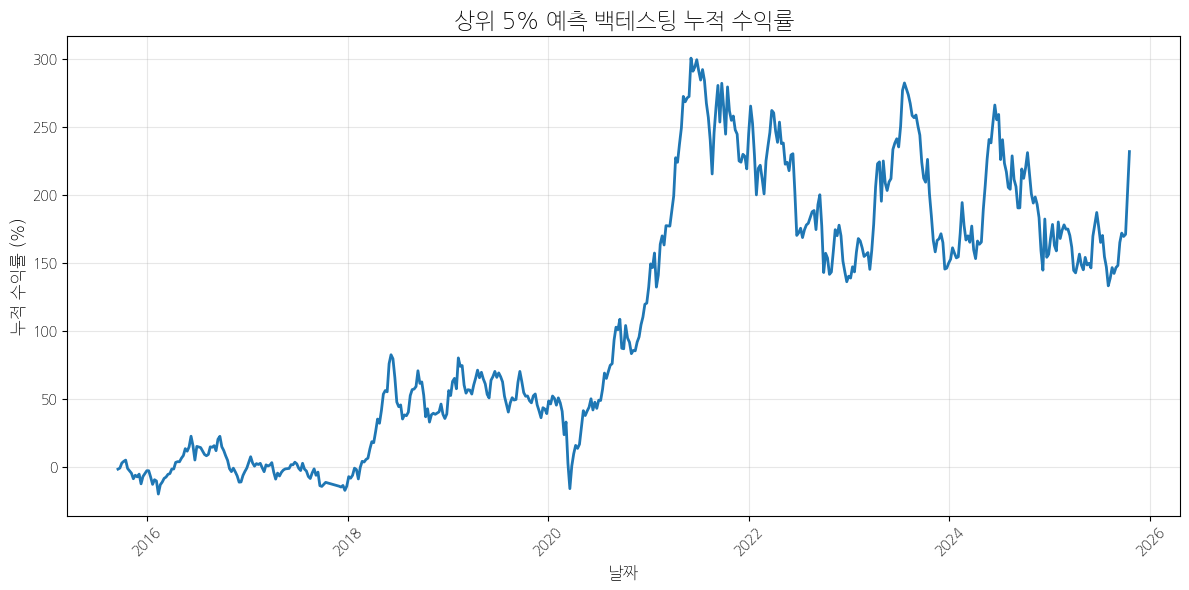

,week,n_predictions,avg_return,returns,tickers,cumulative_return,peak,drawdown
0,2015-09-18,25,-0.015185,"[-0.239189249050573, -0.0747600752091092, 0.01...","[005960, 013520, 092200, 012030, 004980, 00126...",-0.015185,-0.015185,0.000000
1,2015-09-25,25,0.008127,"[-0.0584962066816084, -0.0716967513215611, -0....","[001470, 025620, 005960, 118000, 004060, 00532...",-0.007181,-0.007181,0.000000
2,2015-10-02,25,0.037086,"[0.1031842362352308, 0.0178895647507751, 0.093...","[014910, 006380, 118000, 013700, 006490, 00178...",0.029638,0.029638,0.000000
3,2015-10-09,25,0.012269,"[0.0337522868048915, -0.0149815536156169, -0.0...","[023960, 007860, 058860, 004270, 004060, 10228...",0.042271,0.042271,0.000000
4,2015-10-16,25,0.008578,"[0.3858465129567853, -0.061223460088118, 0.108...","[001380, 014990, 009810, 118000, 006740, 00860...",0.051212,0.051212,0.000000
5,2015-10-23,25,-0.058169,"[0.0423955589676855, -0.1095986264128944, -0.1...","[074610, 010600, 001380, 092220, 008600, 00634...",-0.009936,0.051212,-0.061148
6,2015-10-30,25,-0.017313,"[0.034528707544466, -0.0889913404131595, -0.00...","[001380, 010580, 027970, 128940, 016090, 00147...",-0.027076,0.051212,-0.078289
7,2015-11-06,25,-0.018361,"[0.1611832726397329, -0.1220326074369321, 0.02...","[027740, 004140, 018880, 001260, 031820, 01082...",-0.044940,0.051212,-0.096152
8,2015-11-13,25,-0.042840,"[-0.2131363198379644, -0.047367688822889, -0.1...","[002630, 009420, 074610, 004310, 005960, 00272...",-0.085855,0.051212,-0.137067
9,2015-11-20,25,0.028271,"[0.0253273791482871, 0.1952746523054174, 0.033...","[005110, 014130, 128940, 003060, 006490, 02774...",-0.060011,0.051212,-0.111223


In [31]:
# 12. 상위 5% 예측 백테스팅
import numpy as np
from sklearn.metrics import roc_auc_score, average_precision_score
from xgboost import XGBClassifier

# 백테스팅 설정
weeks_sorted = np.array(sorted(feat_df['날짜'].unique()))
min_train_weeks = 52  # 최소 1년 학습 데이터
backtest_weeks = weeks_sorted[min_train_weeks:]

print(f"백테스팅 기간: {len(backtest_weeks)}주 ({backtest_weeks[0]} ~ {backtest_weeks[-1]})")

# 주별 백테스팅 결과 저장
backtest_results = []

for i, current_week in enumerate(backtest_weeks):
    # 현재 주 이전 데이터로 학습
    train_mask = feat_df['날짜'] < current_week
    X_train_bt = feat_df.loc[train_mask, feature_cols].values
    y_train_bt = percentile_df.loc[train_mask, 'top5pct'].values
    
    # 현재 주 데이터로 예측
    current_mask = feat_df['날짜'] == current_week
    current_df = feat_df.loc[current_mask].copy()
    
    if len(current_df) == 0 or len(X_train_bt) == 0:
        continue
    
    # 모델 학습
    bt_model = XGBClassifier(
        n_estimators=300,  # 빠른 학습을 위해 줄임
        max_depth=6,
        learning_rate=0.03,
        subsample=0.8,
        colsample_bytree=0.8,
        objective='binary:logistic',
        eval_metric='auc',
        tree_method='hist',
        random_state=42,
    )
    bt_model.fit(X_train_bt, y_train_bt)
    
    # 현재 주 예측
    X_current = current_df[feature_cols].values
    current_df['pred_proba'] = bt_model.predict_proba(X_current)[:, 1]
    
    # 상위 5% 예측 종목 선택 (실제 상위 5% 개수와 동일하게)
    n_stocks = len(current_df)
    n_top5 = max(1, int(n_stocks * 0.05))  # 최소 1개
    
    top5_predictions = current_df.nlargest(n_top5, 'pred_proba')
    
    # 실제 수익률 계산
    actual_returns = top5_predictions['weekly_return'].values
    avg_return = np.mean(actual_returns)
    
    # 결과 저장
    backtest_results.append({
        'week': current_week,
        'n_predictions': len(top5_predictions),
        'avg_return': avg_return,
        'returns': actual_returns.tolist(),
        'tickers': top5_predictions['ticker'].tolist()
    })
    
    if (i + 1) % 20 == 0:
        print(f"진행률: {i+1}/{len(backtest_weeks)}주 완료")

# 백테스팅 결과 분석
bt_df = pd.DataFrame(backtest_results)
bt_df['week'] = pd.to_datetime(bt_df['week'])

# 성과 지표 계산
all_returns = []
for returns_list in bt_df['returns']:
    all_returns.extend(returns_list)

all_returns = np.array(all_returns)

# 기본 통계
total_weeks = len(bt_df)
avg_weekly_return = np.mean(bt_df['avg_return'])
std_weekly_return = np.std(bt_df['avg_return'])
win_rate = np.mean(bt_df['avg_return'] > 0) * 100

# 누적 수익률
bt_df['cumulative_return'] = (1 + bt_df['avg_return']).cumprod() - 1
total_return = bt_df['cumulative_return'].iloc[-1]

# 샤프 비율 (연간화)
sharpe_ratio = (avg_weekly_return * 52) / (std_weekly_return * np.sqrt(52))

# 최대 낙폭 (Drawdown)
bt_df['peak'] = bt_df['cumulative_return'].expanding().max()
bt_df['drawdown'] = bt_df['cumulative_return'] - bt_df['peak']
max_drawdown = bt_df['drawdown'].min()

print("=== 백테스팅 결과 ===")
print(f"백테스팅 기간: {total_weeks}주")
print(f"평균 주간 수익률: {avg_weekly_return:.4f} ({avg_weekly_return*100:.2f}%)")
print(f"주간 수익률 표준편차: {std_weekly_return:.4f}")
print(f"승률: {win_rate:.1f}%")
print(f"총 수익률: {total_return:.4f} ({total_return*100:.2f}%)")
print(f"연간화 샤프 비율: {sharpe_ratio:.4f}")
print(f"최대 낙폭: {max_drawdown:.4f} ({max_drawdown*100:.2f}%)")

# 결과 저장
bt_save_path = os.path.join(analysis_dataset_dir, 'backtest_results_top5pct.csv')
bt_df.to_csv(bt_save_path, index=False)

# 성과 요약 저장
performance_summary = {
    'total_weeks': total_weeks,
    'avg_weekly_return': avg_weekly_return,
    'std_weekly_return': std_weekly_return,
    'win_rate': win_rate,
    'total_return': total_return,
    'sharpe_ratio': sharpe_ratio,
    'max_drawdown': max_drawdown,
    'avg_return_all_trades': np.mean(all_returns),
    'std_return_all_trades': np.std(all_returns)
}

summary_path = os.path.join(analysis_dataset_dir, 'backtest_performance_summary.json')
import json
with open(summary_path, 'w') as f:
    json.dump(performance_summary, f, indent=2)

print(f"✅ 백테스팅 결과 저장: {bt_save_path}")
print(f"✅ 성과 요약 저장: {summary_path}")

# 누적 수익률 차트
plt.figure(figsize=(12, 6))
plt.plot(bt_df['week'], bt_df['cumulative_return'] * 100, linewidth=2)
plt.title('상위 5% 예측 백테스팅 누적 수익률', fontsize=16, fontweight='bold')
plt.xlabel('날짜', fontsize=12)
plt.ylabel('누적 수익률 (%)', fontsize=12)
plt.grid(True, alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

display(bt_df.head(10))
